# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


In [2]:

# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import nltk
import os

from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer

print("Libraries imported successfully!")


# Step 2: Download resources needed for text processing

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")



Libraries imported successfully!
NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [3]:

# Step 3: Load the dataset

df = pd.read_csv('amazon_reviews_lab.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [4]:

# Step 4: Explore the dataset

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

display(df.describe(include='all').T)


Column names:
['product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label', 'review_length_words']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB

Missing values:
product_id             0
rating                 0
review_text            0
rev

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,997,40,0972683275,218,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,997.0,NaN,NaN,NaN,4.129388,1.280181,1.0,4.0,5.0,5.0,5.0
review_text,997,997,This film is definitely not for anyone who is ...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_summary,997,938,Works great,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_time_raw,997,722,"09 18, 2013",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unix_review_time,997.0,NaN,NaN,NaN,1344766257.171515,44114204.839312,958089600.0,1311897600.0,1356048000.0,1379462400.0,1405555200.0
timestamp,997,722,2013-09-18,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentiment_label,997,3,positive,768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_length_words,997.0,NaN,NaN,NaN,146.374122,216.12677,5.0,32.0,67.0,165.0,2079.0


In [5]:

# Step 5: Identify the text column

possible_text_columns = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ['review', 'text', 'comment', 'content'])
]

print("Possible review text columns:", possible_text_columns)


Possible review text columns: ['review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'review_length_words']


In [6]:

# Replace 'reviewText' with the actual column name printed above

TEXT_COLUMN = 'review_text'

# Keep rows that contain review text
df = df.dropna(subset=[TEXT_COLUMN]).copy()

# Convert all reviews to strings
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)

print("Number of reviews available:", len(df))
display(df[[TEXT_COLUMN]].head())


Number of reviews available: 997


,review_text
0,This film is definitely not for anyone who is ...
1,This movie was playing at Radio City Music Hal...
2,I would love to buy this movie as I have been ...
3,The advertisment for this DVD on Amazon was in...
4,I bought some of these to try with a light usi...


In [7]:

# Step 6: Set up text preprocessing

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Handle missing values
    if pd.isna(text):
        return []

    # Convert to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Keep letters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenize the text
    tokens = word_tokenize(text)

    # Remove stopwords and very short tokens, then lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return cleaned_tokens

# Apply preprocessing to every review
df['tokens'] = df[TEXT_COLUMN].apply(preprocess_text)

# Join tokens back into cleaned text for later analysis
df['cleaned_text'] = df['tokens'].apply(lambda tokens: ' '.join(tokens))

display(df[[TEXT_COLUMN, 'cleaned_text']].head())


,review_text,cleaned_text
0,This film is definitely not for anyone who is ...,film definitely anyone especially fond indepen...
1,This movie was playing at Radio City Music Hal...,movie playing radio city music hall back day m...
2,I would love to buy this movie as I have been ...,would love buy movie hannibal missouri mark tw...
3,The advertisment for this DVD on Amazon was in...,advertisment dvd amazon incorrect ad stated dv...
4,I bought some of these to try with a light usi...,bought try light using work advertised check m...


In [8]:

# Step 7: Find the most frequent words

from collections import Counter

# Combine all cleaned tokens into one list
all_words = [
    word
    for tokens in df['tokens']
    for word in tokens
]

# Count how often each word appears
word_counts = Counter(all_words)

# Display the 15 most common words
most_common_words = word_counts.most_common(15)

print("Top 15 Most Frequent Words:")
display(pd.DataFrame(most_common_words, columns=['Word', 'Frequency']))


Top 15 Most Frequent Words:


,Word,Frequency
0,nook,1580
1,book,986
2,one,596
3,kindle,592
4,screen,536
5,like,474
6,read,464
7,work,463
8,great,444
9,tablet,444


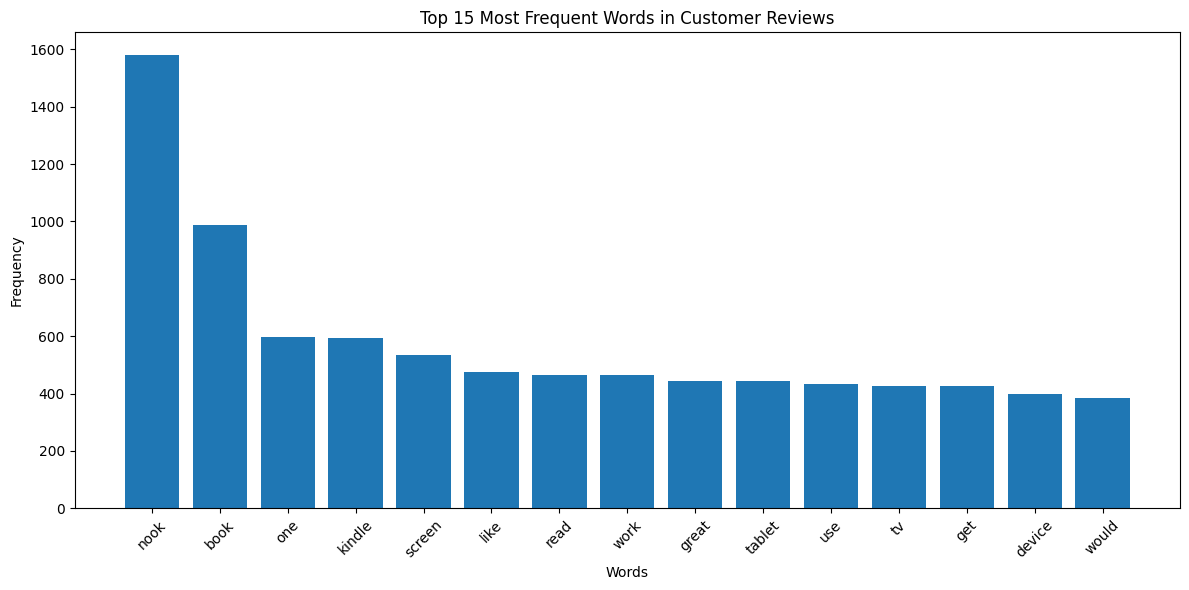

In [9]:

# Step 8: Visualize the most frequent words

words = [item[0] for item in most_common_words]
frequencies = [item[1] for item in most_common_words]

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies)

plt.title('Top 15 Most Frequent Words in Customer Reviews')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:

# Step 9: Find the most common bigrams

from nltk import bigrams

# Create pairs of consecutive words from each review
all_bigrams = [
    pair
    for tokens in df['tokens']
    for pair in bigrams(tokens)
]

# Count the frequency of each bigram
bigram_counts = Counter(all_bigrams)

# Get the 15 most common bigrams
most_common_bigrams = bigram_counts.most_common(15)

# Display the results
bigram_table = pd.DataFrame(
    [
        (' '.join(pair), frequency)
        for pair, frequency in most_common_bigrams
    ],
    columns=['Bigram', 'Frequency']
)

print("Top 15 Most Frequent Bigrams:")
display(bigram_table)


Top 15 Most Frequent Bigrams:


,Bigram,Frequency
0,barnes noble,166
1,nook color,135
2,battery life,98
3,touch screen,96
4,sd card,90
5,nook hd,80
6,work great,65
7,nook tablet,64
8,kindle fire,61
9,work well,59


### Part 1 Reflection: Natural Language Processing

The NLP analysis helped identify common topics in customer reviews by cleaning the text and counting frequently used words and two-word phrases. The most frequent words included “nook,” “book,” and “kindle,” showing that customers often discussed reading devices and books.

The bigram analysis identified phrases such as “barnes noble,” “nook color,” “battery life,” and “touch screen.” These phrases suggest that customers discussed specific devices, product features, and performance. The appearance of “battery life” and “customer service” also highlights areas that a business may want to investigate further.

This analysis can help a business understand recurring customer concerns and identify topics for further investigation. However, word frequency alone cannot determine whether customers were satisfied or dissatisfied. The results should be considered alongside review ratings and sentiment analysis before making business decisions.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [11]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


In [12]:

# Step 1: Import libraries and load the dataset

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('amazon_reviews_lab.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Dataset shape: (997, 9)
Columns: ['product_id', 'rating', 'review_text', 'review_summary', 'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label', 'review_length_words']


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [13]:

# Step 2: Convert timestamps to datetime format

df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    errors='coerce'
)

print("Earliest review date:", df['timestamp'].min())
print("Latest review date:", df['timestamp'].max())
print("Missing timestamps:", df['timestamp'].isna().sum())


Earliest review date: 2000-05-12 00:00:00
Latest review date: 2014-07-17 00:00:00
Missing timestamps: 0


In [14]:

# Step 3: Calculate monthly review counts and average ratings

# Remove rows with missing dates and sort by date
df_time = df.dropna(subset=['timestamp']).copy()

# Set timestamp as the index
df_time = df_time.set_index('timestamp').sort_index()

# Count reviews per month
monthly_review_count = df_time['rating'].resample('MS').count()

# Calculate average rating per month
monthly_avg_rating = df_time['rating'].resample('MS').mean()

# Display the results
print("Monthly review counts:")
display(monthly_review_count.head(12))

print("Monthly average ratings:")
display(monthly_avg_rating.head(12))


Monthly review counts:


timestamp
2000-05-01    1
2000-06-01    0
2000-07-01    0
2000-08-01    0
2000-09-01    0
2000-10-01    0
2000-11-01    0
2000-12-01    0
2001-01-01    0
2001-02-01    0
2001-03-01    0
2001-04-01    0
Freq: MS, Name: rating, dtype: int64

Monthly average ratings:


timestamp
2000-05-01    2.0
2000-06-01    NaN
2000-07-01    NaN
2000-08-01    NaN
2000-09-01    NaN
2000-10-01    NaN
2000-11-01    NaN
2000-12-01    NaN
2001-01-01    NaN
2001-02-01    NaN
2001-03-01    NaN
2001-04-01    NaN
Freq: MS, Name: rating, dtype: float64

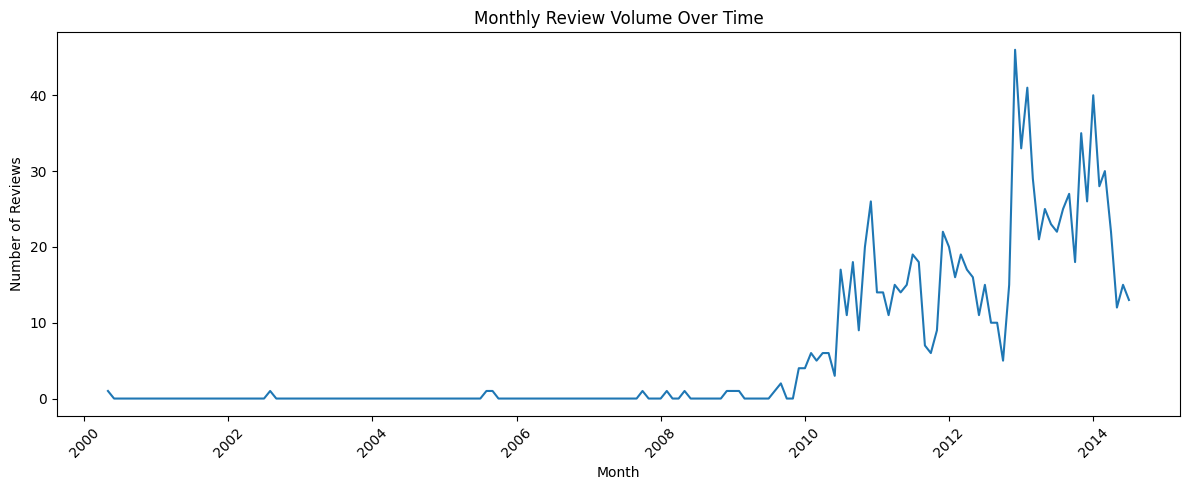

In [15]:

# Step 4: Plot monthly review volume over time

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_review_count.index,
    monthly_review_count.values
)

plt.title('Monthly Review Volume Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


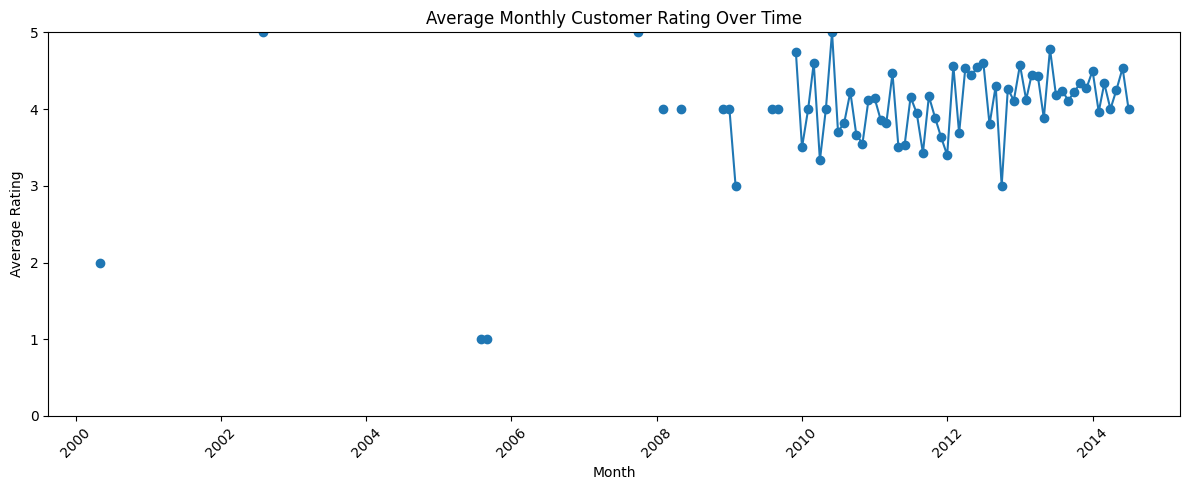

In [16]:

# Step 5: Plot average monthly rating over time

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    marker='o'
)

plt.title('Average Monthly Customer Rating Over Time')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


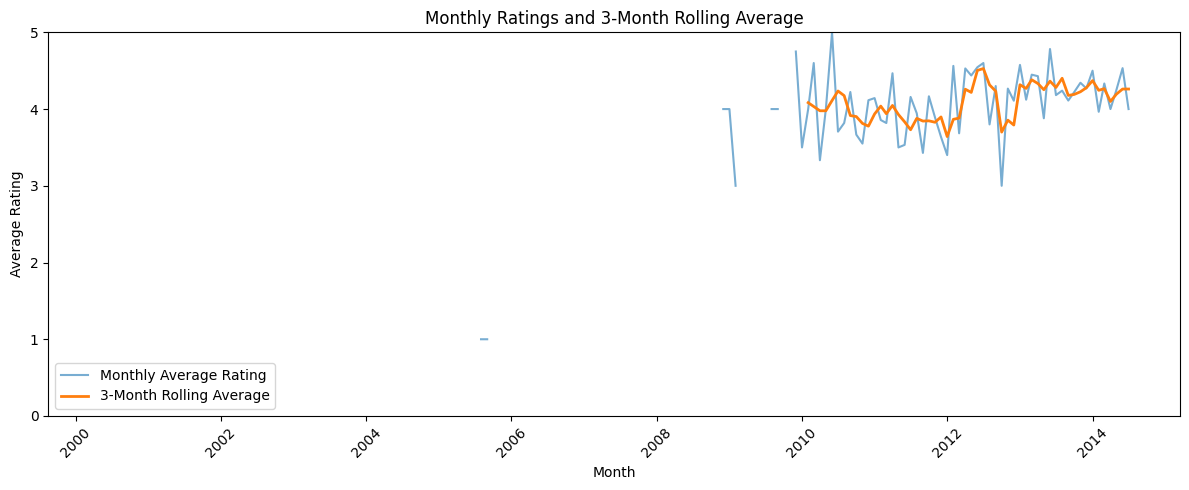

In [17]:

# Step 6: Calculate and plot the 3-month rolling average

rolling_avg_rating = monthly_avg_rating.rolling(
    window=3,
    min_periods=3
).mean()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    label='Monthly Average Rating',
    alpha=0.6
)

plt.plot(
    rolling_avg_rating.index,
    rolling_avg_rating.values,
    label='3-Month Rolling Average',
    linewidth=2
)

plt.title('Monthly Ratings and 3-Month Rolling Average')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(0, 5)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Observations: 54
Months with zero reviews: 0
count    54.0
mean     17.9
std       9.8
min       3.0
25%      11.0
50%      16.5
75%      22.8
max      46.0
Name: rating, dtype: float64


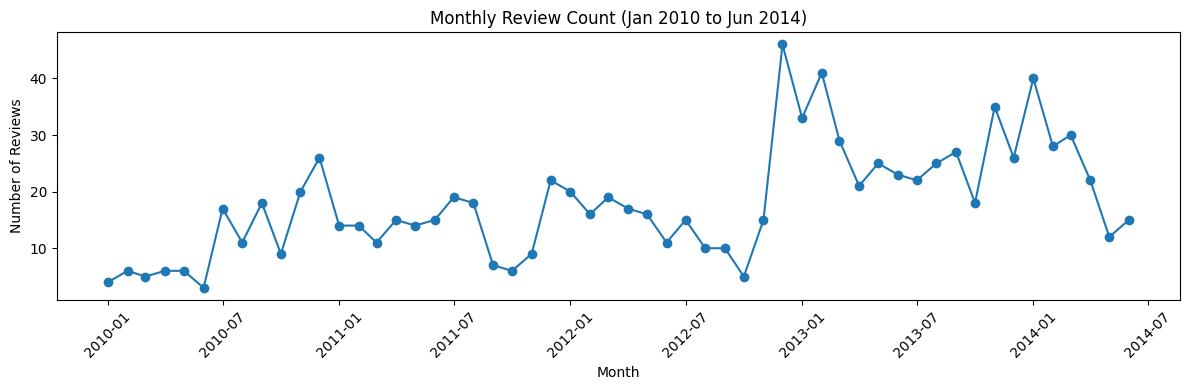

In [18]:
# Step 7: Select the usable period for forecasting

# Reviews are sparse before 2010, and July 2014 is a partial month (data ends 2014-07-17)
ts = monthly_review_count.loc['2010-01-01':'2014-06-01'].astype(float)

print("Observations:", len(ts))
print("Months with zero reviews:", (ts == 0).sum())
print(ts.describe().round(1))

plt.figure(figsize=(12, 4))
plt.plot(ts.index, ts.values, marker='o')
plt.title('Monthly Review Count (Jan 2010 to Jun 2014)')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Raw counts             ADF p = 0.0069 (stationary) | KPSS p = 0.0122 (NON-stationary)
Log-transformed        ADF p = 0.0054 (stationary) | KPSS p = 0.0108 (NON-stationary)
First difference       ADF p = 0.0001 (stationary) | KPSS p = 0.1000 (stationary)
Log + first difference ADF p = 0.0003 (stationary) | KPSS p = 0.1000 (stationary)


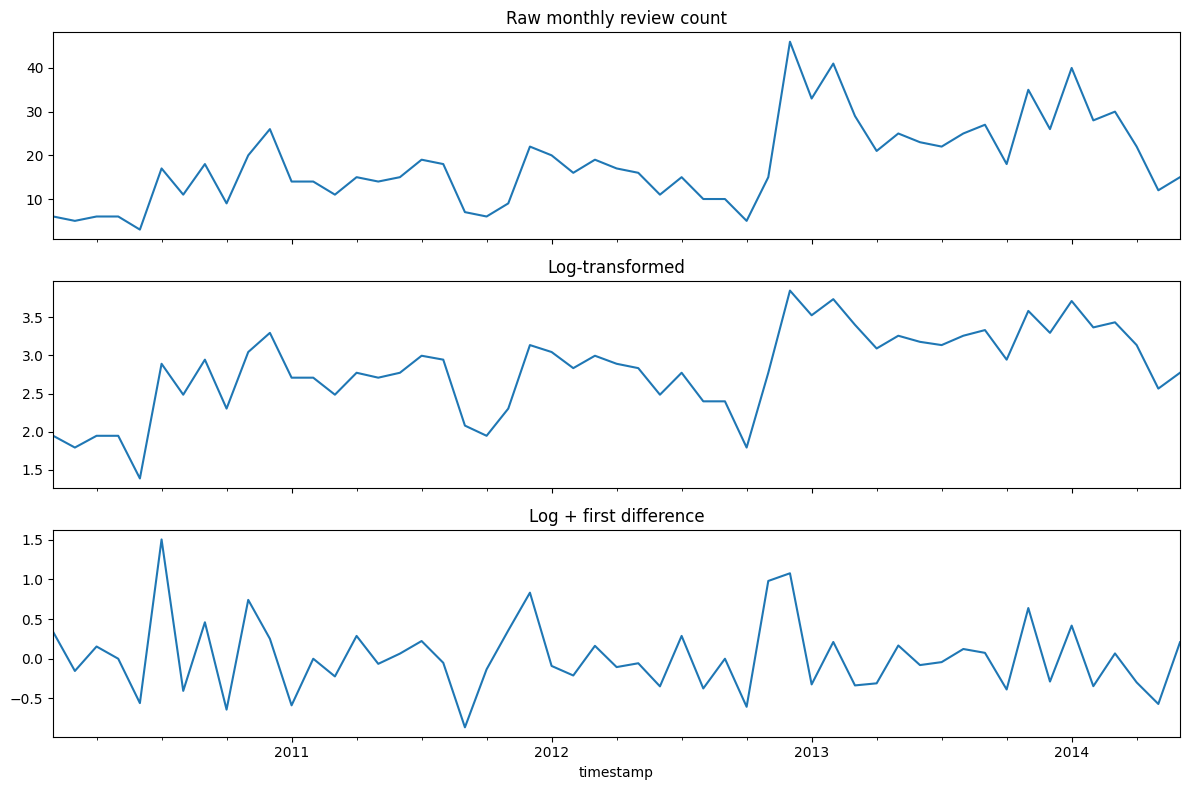

In [19]:
# Step 8: Stationarity tests (ADF and KPSS) with transformations

import warnings
from statsmodels.tsa.stattools import adfuller, kpss
warnings.filterwarnings("ignore")

def stationarity_report(series, name):
    series = series.dropna()
    adf_p = adfuller(series)[1]
    kpss_p = kpss(series, regression='c', nlags='auto')[1]
    print(f"{name:<22} ADF p = {adf_p:.4f} ({'stationary' if adf_p < 0.05 else 'NON-stationary'})"
          f" | KPSS p = {kpss_p:.4f} ({'stationary' if kpss_p > 0.05 else 'NON-stationary'})")

# Transformations
ts_log = np.log1p(ts)               # stabilizes variance
ts_diff = ts.diff().dropna()        # removes trend
ts_log_diff = ts_log.diff().dropna()

stationarity_report(ts,          "Raw counts")
stationarity_report(ts_log,      "Log-transformed")
stationarity_report(ts_diff,     "First difference")
stationarity_report(ts_log_diff, "Log + first difference")

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ts.plot(ax=axes[0], title='Raw monthly review count')
ts_log.plot(ax=axes[1], title='Log-transformed')
ts_log_diff.plot(ax=axes[2], title='Log + first difference')
plt.tight_layout()
plt.show()

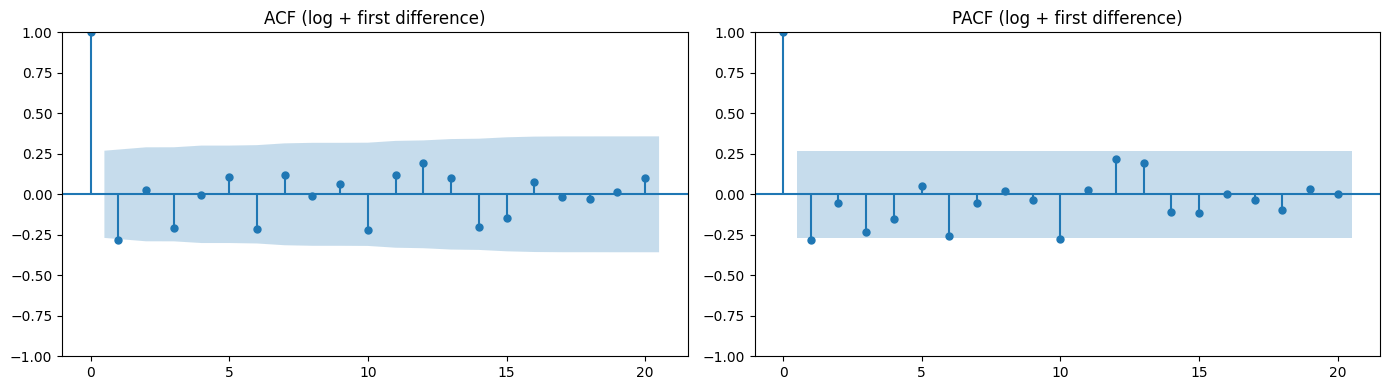

In [20]:
# Step 9: ACF and PACF to choose ARIMA orders (p, q)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ts_log_diff, lags=20, ax=axes[0])
plot_pacf(ts_log_diff, lags=20, ax=axes[1], method='ywm')
axes[0].set_title('ACF (log + first difference)')
axes[1].set_title('PACF (log + first difference)')
plt.tight_layout()
plt.show()

In [21]:
# Step 10: Fit candidate ARIMA models on a chronological train/test split

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

split = int(len(ts_log) * 0.8)
train_log, test_log = ts_log.iloc[:split], ts_log.iloc[split:]
test_actual = np.expm1(test_log)          # back to review counts

print(f"Train: {len(train_log)} months | Test: {len(test_log)} months "
      f"({test_log.index[0].date()} to {test_log.index[-1].date()})")

candidate_orders = [(1,1,0), (0,1,1), (1,1,1), (2,1,1), (1,1,2), (2,1,2)]
results, fitted_models = [], {}

for order in candidate_orders:
    model_fit = ARIMA(train_log, order=order).fit()
    forecast = np.expm1(model_fit.forecast(steps=len(test_log)))
    fitted_models[order] = model_fit
    results.append({
        'Model': f'ARIMA{order}',
        'AIC': round(model_fit.aic, 1),
        'BIC': round(model_fit.bic, 1),
        'MAE': round(mean_absolute_error(test_actual, forecast), 2),
        'RMSE': round(np.sqrt(mean_squared_error(test_actual, forecast)), 2),
    })

# Baselines
naive = np.repeat(np.expm1(train_log.iloc[-1]), len(test_log))
train_mean = np.repeat(np.expm1(train_log).mean(), len(test_log))
for name, pred in [('Naive (last value)', naive), ('Training mean', train_mean)]:
    results.append({
        'Model': name, 'AIC': None, 'BIC': None,
        'MAE': round(mean_absolute_error(test_actual, pred), 2),
        'RMSE': round(np.sqrt(mean_squared_error(test_actual, pred)), 2),
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values('RMSE'))

best_order = (results_df.dropna(subset=['AIC'])
              .sort_values('AIC').iloc[0]['Model'])
print("Lowest AIC:", best_order)

Train: 43 months | Test: 11 months (2013-08-01 to 2014-06-01)


,Model,AIC,BIC,MAE,RMSE
1,"ARIMA(0, 1, 1)",57.6,61.0,6.93,8.37
0,"ARIMA(1, 1, 0)",58.5,61.9,7.03,8.50
6,Naive (last value),NaN,NaN,7.09,8.57
2,"ARIMA(1, 1, 1)",57.0,62.3,7.28,8.75
4,"ARIMA(1, 1, 2)",59.0,66.0,7.36,8.83
3,"ARIMA(2, 1, 1)",59.0,66.0,7.40,8.87
5,"ARIMA(2, 1, 2)",60.8,69.5,7.47,8.95
7,Training mean,NaN,NaN,10.17,12.18


Lowest AIC: ARIMA(1, 1, 1)


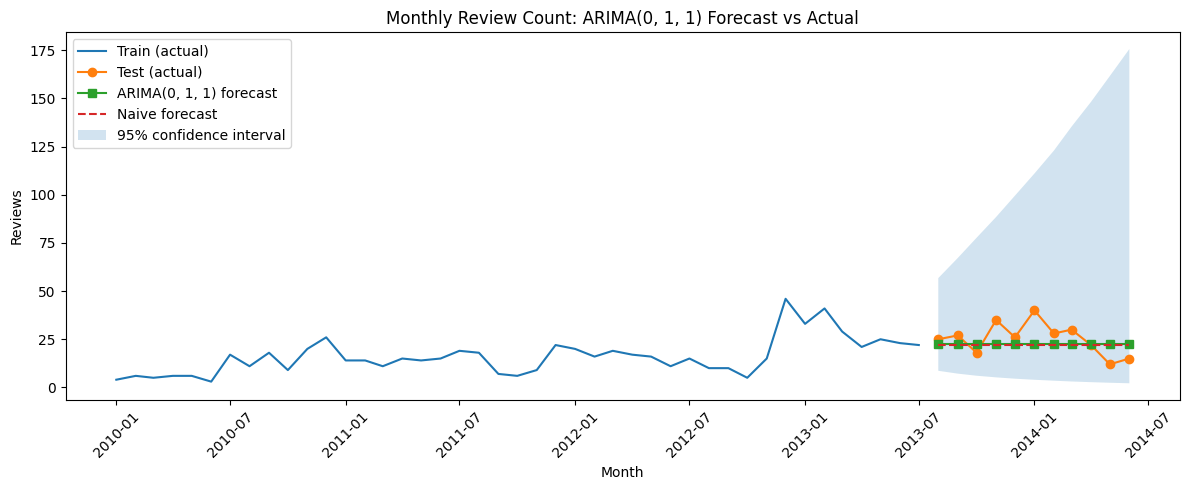

Ljung-Box p-value (lag 10): 0.6672 -> residuals look like white noise
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3633      0.156     -2.336      0.020      -0.668      -0.058
sigma2         0.2089      0.034      6.115      0.000       0.142       0.276


In [22]:
# Step 11: Forecast vs actual for the selected model, with 95% confidence interval

from statsmodels.stats.diagnostic import acorr_ljungbox

best_order = (0, 1, 1)
best_fit = fitted_models[best_order]

fc = best_fit.get_forecast(steps=len(test_log))
mean_fc = np.expm1(fc.predicted_mean)
ci = np.expm1(fc.conf_int())

plt.figure(figsize=(12, 5))
plt.plot(np.expm1(train_log).index, np.expm1(train_log), label='Train (actual)')
plt.plot(test_actual.index, test_actual, label='Test (actual)', marker='o')
plt.plot(mean_fc.index, mean_fc, label=f'ARIMA{best_order} forecast', marker='s')
plt.plot(test_actual.index, naive, linestyle='--', label='Naive forecast')
plt.fill_between(ci.index, ci.iloc[:, 0].clip(lower=0), ci.iloc[:, 1],
                 alpha=0.2, label='95% confidence interval')
plt.title(f'Monthly Review Count: ARIMA{best_order} Forecast vs Actual')
plt.xlabel('Month'); plt.ylabel('Reviews')
plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Residual diagnostics: residuals should look like random noise
resid = best_fit.resid.iloc[1:]          # first residual is an artifact of differencing
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
print("Ljung-Box p-value (lag 10):", round(lb['lb_pvalue'].iloc[0], 4),
      "-> residuals look like white noise" if lb['lb_pvalue'].iloc[0] > 0.05
      else "-> some autocorrelation remains")

print(best_fit.summary().tables[1])

### Part 2 Reflection: Stationarity, Forecasting, and Review Activity

**Data window:** Reviews before 2010 are sparse (16 in total), so I modeled January 2010 to June 2014 (54 months) and excluded July 2014 because the data ends mid-month. Monthly volume averaged about 18 reviews (range 3 to 46). It started at roughly 4 to 6 reviews per month in early 2010, held around 10 to 20 through 2011 and 2012, peaked at 46 in late 2012, and stayed at 20 to 40 through 2013 and early 2014 before falling to 12 to 15 in May and June 2014. Bumps appear in the holiday periods (late 2010, late 2012, late 2013 and January 2014), which is consistent with devices being gifted and reviewed after the holidays.

**Stationarity:** The raw series gave conflicting results (ADF p = 0.0069 says stationary, KPSS p = 0.0122 says non-stationary), which points to a trend. A log transformation did not resolve this, but one round of differencing did: ADF p = 0.0001 and KPSS p = 0.10 (the lowest-precision value statsmodels reports), so both tests agree on stationarity. I therefore used d = 1 and modeled log-transformed counts to stabilize variance as volume grew.

**Model selection:** The ACF and PACF of the differenced series showed a single borderline spike at lag 1 (about -0.28) and nothing else outside the confidence band, including at lag 12. This weakly supports an MA(1) term and gives no evidence of yearly seasonality. I compared six ARIMA orders. ARIMA(0,1,1) had the lowest BIC (61.0) and a near-best AIC (57.6). ARIMA(1,1,1) had a slightly lower AIC (57.0), but the difference is too small to justify the extra parameter. The MA(1) coefficient (-0.363, p = 0.020) is statistically significant.

**Forecast accuracy:** On the 11 held-out months (Aug 2013 to Jun 2014), ARIMA(0,1,1) had MAE 6.93 and RMSE 8.37, only slightly better than a naive last-value forecast (RMSE 8.57) and much better than the training mean (RMSE 12.18). The forecast is essentially flat at about 22 reviews per month, and the 95% interval is very wide and fans out over time, which reflects real uncertainty (the interval is also back-transformed from the log scale). Most actual values fall inside the interval. The Ljung-Box test (p = 0.667) shows the residuals look like white noise, so the model captured the available structure, but with an average of about 18 reviews per month and a volatile test period (a spike of 40 in January 2014 and a drop to 12 to 15 in May to June 2014), the forecast is only a rough guide.

**Business implication:** Review volume is best planned as a range, not a point estimate. For example, staffing moderation or support capacity should use the interval rather than the single forecast value. With only 54 months of data, a longer history or seasonal terms would be needed for reliable forecasting.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [23]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


In [24]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load the dataset
df = pd.read_csv('amazon_reviews_lab.csv')

# Keep rows that have both review text and a rating
df = df.dropna(subset=['review_text', 'rating']).copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nRating distribution:")
print(df['rating'].value_counts().sort_index())

display(df[['review_text', 'rating']].head())


Dataset loaded successfully!
Dataset shape: (997, 9)

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64


,review_text,rating
0,This film is definitely not for anyone who is ...,2
1,This movie was playing at Radio City Music Hal...,5
2,I would love to buy this movie as I have been ...,1
3,The advertisment for this DVD on Amazon was in...,1
4,I bought some of these to try with a light usi...,5


In [25]:

# Separate the review text (X) from the ratings (y)
X = df['review_text'].astype(str)
y = df['rating'].astype(int)

# Convert review text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(X)

print("Original number of reviews:", len(X))
print("TF-IDF matrix shape:", X_tfidf.shape)
print("Number of rating classes:", y.nunique())
print("Rating classes:", sorted(y.unique()))


Original number of reviews: 997
TF-IDF matrix shape: (997, 3000)
Number of rating classes: 5
Rating classes: [1, 2, 3, 4, 5]


In [26]:

# Split the original review text and ratings
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit TF-IDF using training reviews only
tfidf = TfidfVectorizer(
    max_features=3000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])

print("\nTraining rating distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting rating distribution:")
print(y_test.value_counts().sort_index())


Training reviews: 797
Testing reviews: 200
Number of TF-IDF features: 3000

Training rating distribution:
rating
1     70
2     38
3     75
4    150
5    464
Name: count, dtype: int64

Testing rating distribution:
rating
1     17
2     10
3     19
4     38
5    116
Name: count, dtype: int64


In [27]:

# Create a label encoder
label_encoder = LabelEncoder()

# Fit on the training ratings and transform both sets
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Convert labels into one-hot encoded vectors
y_train_onehot = keras.utils.to_categorical(
    y_train_encoded,
    num_classes=5
)

y_test_onehot = keras.utils.to_categorical(
    y_test_encoded,
    num_classes=5
)

print("Rating classes:", label_encoder.classes_)
print("Training labels shape:", y_train_onehot.shape)
print("Testing labels shape:", y_test_onehot.shape)

print("\nExample rating:", y_train.iloc[0])
print("Encoded label:", y_train_encoded[0])
print("One-hot label:", y_train_onehot[0])


Rating classes: [1 2 3 4 5]
Training labels shape: (797, 5)
Testing labels shape: (200, 5)

Example rating: 4
Encoded label: 3
One-hot label: [0. 0. 0. 1. 0.]


In [28]:

# Build the neural network
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(5, activation='softmax')
])

# Configure the model for training
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display the model architecture
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                192064    
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 32)                2080      
                                                                 
 dense_2 (Dense)             (None, 5)                 165       
                                                                 
Total params: 194,309
Trainable params: 194,309
Non-trainable params: 0
_________________________________________________________________


In [29]:

# Train the neural network
history = model.fit(
    X_train.toarray(),
    y_train_onehot,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/15
20/20 [==============================] - 1s 15ms/step - loss: 1.5668 - accuracy: 0.4207 - val_loss: 1.5070 - val_accuracy: 0.5813
Epoch 2/15
20/20 [==============================] - 0s 5ms/step - loss: 1.3998 - accuracy: 0.5840 - val_loss: 1.3188 - val_accuracy: 0.5813
Epoch 3/15
20/20 [==============================] - 0s 5ms/step - loss: 1.1873 - accuracy: 0.5824 - val_loss: 1.2106 - val_accuracy: 0.5813
Epoch 4/15
20/20 [==============================] - 0s 5ms/step - loss: 1.0664 - accuracy: 0.5824 - val_loss: 1.1687 - val_accuracy: 0.5813
Epoch 5/15
20/20 [==============================] - 0s 5ms/step - loss: 0.9570 - accuracy: 0.5824 - val_loss: 1.1450 - val_accuracy: 0.5813
Epoch 6/15
20/20 [==============================] - 0s 5ms/step - loss: 0.8377 - accuracy: 0.6138 - val_loss: 1.1278 - val_accuracy: 0.5875
Epoch 7/15
20/20 [==============================] - 0s 6ms/step - loss: 0.7232 - accuracy: 0.6876 - val_loss: 1.1212 - val_accuracy: 0.5938
Epoch 8/15
20/20 [=

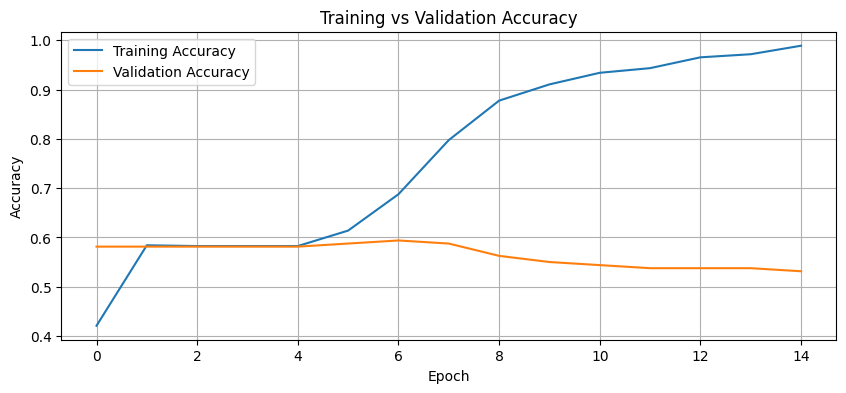

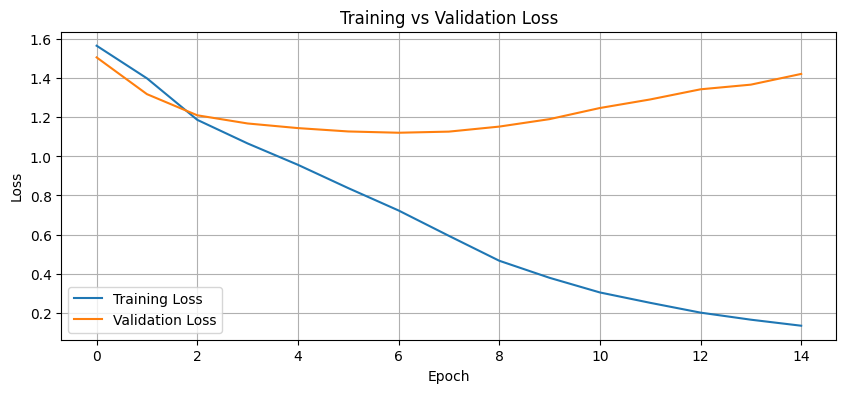

In [30]:

# Plot training and validation accuracy
plt.figure(figsize=(10, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [31]:

# Predict ratings for the test reviews
y_pred_prob = model.predict(X_test.toarray())

# Convert predicted probabilities into rating classes
y_pred_encoded = np.argmax(y_pred_prob, axis=1)
y_pred = label_encoder.inverse_transform(y_pred_encoded)

# Convert the one-hot encoded test labels back to rating classes
y_test_actual = label_encoder.inverse_transform(
    np.argmax(y_test_onehot, axis=1)
)

# Display test accuracy
test_loss, test_accuracy = model.evaluate(
    X_test.toarray(),
    y_test_onehot,
    verbose=0
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_actual,
    y_pred,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_actual,
    y_pred,
    labels=[1, 2, 3, 4, 5]
))


7/7 [==============================] - 0s 2ms/step
Test accuracy: 0.5450
Test loss: 1.4777

Classification Report:
              precision    recall  f1-score   support

           1       0.25      0.06      0.10        17
           2       0.00      0.00      0.00        10
           3       0.08      0.05      0.06        19
           4       0.26      0.21      0.23        38
           5       0.65      0.85      0.74       116

    accuracy                           0.55       200
   macro avg       0.25      0.24      0.23       200
weighted avg       0.45      0.55      0.49       200


Confusion Matrix:
[[ 1  0  3  3 10]
 [ 2  0  3  2  3]
 [ 1  0  1  5 12]
 [ 0  0  1  8 29]
 [ 0  0  4 13 99]]


In [32]:
# Step 12: Baselines to put the neural network's accuracy in context

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Baseline 1: always predict the most common training class
majority_class = np.bincount(y_train_encoded).argmax()
majority_pred = np.full(len(y_test_encoded), majority_class)

# Baseline 2: logistic regression on the same TF-IDF features
logreg = LogisticRegression(max_iter=2000).fit(X_train, y_train_encoded)
logreg_pred = logreg.predict(X_test)

# Baseline 3: logistic regression with balanced class weights
logreg_bal = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X_train, y_train_encoded)
logreg_bal_pred = logreg_bal.predict(X_test)

def summarize(name, y_true, y_pred):
    return {
        'Model': name,
        'Test accuracy': round(accuracy_score(y_true, y_pred), 3),
        'Macro F1': round(f1_score(y_true, y_pred, average='macro', zero_division=0), 3),
    }

baseline_df = pd.DataFrame([
    summarize('Always predict 5 stars', y_test_encoded, majority_pred),
    summarize('Logistic regression', y_test_encoded, logreg_pred),
    summarize('Logistic regression (balanced)', y_test_encoded, logreg_bal_pred),
    summarize('Neural network (original)', y_test_encoded, y_pred_encoded),
])
display(baseline_df)

,Model,Test accuracy,Macro F1
0,Always predict 5 stars,0.580,0.147
1,Logistic regression,0.580,0.149
2,Logistic regression (balanced),0.530,0.315
3,Neural network (original),0.545,0.226


In [33]:
# Step 13: Compare neural network variants

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import regularizers

X_train_arr = X_train.toarray()
X_test_arr = X_test.toarray()

# Balanced class weights (keys must be integers 0-4)
cw_values = compute_class_weight('balanced', classes=np.unique(y_train_encoded), y=y_train_encoded)
class_weights = dict(enumerate(cw_values))
print("Class weights:", {k: round(v, 2) for k, v in class_weights.items()})

def build_model(hidden1=64, hidden2=32, dropout=0.3, l2=0.0, optimizer='adam'):
    m = keras.Sequential([
        layers.Input(shape=(X_train_arr.shape[1],)),
        layers.Dense(hidden1, activation='relu', kernel_regularizer=regularizers.l2(l2)),
        layers.Dropout(dropout),
        layers.Dense(hidden2, activation='relu', kernel_regularizer=regularizers.l2(l2)),
        layers.Dense(5, activation='softmax')
    ])
    m.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def run_variant(name, class_weight=None, early_stop=False, **model_kwargs):
    tf.keras.utils.set_random_seed(42)
    m = build_model(**model_kwargs)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True))
    h = m.fit(X_train_arr, y_train_onehot,
              epochs=50 if early_stop else 15, batch_size=32,
              validation_split=0.2, class_weight=class_weight,
              callbacks=callbacks, verbose=0)
    pred = np.argmax(m.predict(X_test_arr, verbose=0), axis=1)
    row = {
        'Experiment': name,
        'Epochs run': len(h.history['loss']),
        'Train acc': round(h.history['accuracy'][-1], 3),
        'Val acc': round(h.history['val_accuracy'][-1], 3),
        'Test acc': round(accuracy_score(y_test_encoded, pred), 3),
        'Macro F1': round(f1_score(y_test_encoded, pred, average='macro', zero_division=0), 3),
    }
    return row, m, pred

rows = []
r, _, _ = run_variant('A. Original (Adam, dropout 0.3)');                       rows.append(r)
r, _, _ = run_variant('B. + class weights', class_weight=class_weights);        rows.append(r)
r, m_c, pred_c = run_variant('C. + L2 1e-3, dropout 0.5, early stopping',
                             class_weight=class_weights, early_stop=True,
                             dropout=0.5, l2=1e-3);                             rows.append(r)
r, _, _ = run_variant('D. SGD optimizer (lr 0.1, momentum 0.9)',
                      class_weight=class_weights,
                      optimizer=keras.optimizers.SGD(learning_rate=0.1, momentum=0.9)); rows.append(r)

results_df = pd.DataFrame(rows)
display(results_df)

Class weights: {0: 2.28, 1: 4.19, 2: 2.13, 3: 1.06, 4: 0.34}


,Experiment,Epochs run,Train acc,Val acc,Test acc,Macro F1
0,"A. Original (Adam, dropout 0.3)",15,0.998,0.550,0.560,0.254
1,B. + class weights,15,0.992,0.581,0.545,0.273
2,"C. + L2 1e-3, dropout 0.5, early stopping",18,0.950,0.562,0.570,0.321
3,"D. SGD optimizer (lr 0.1, momentum 0.9)",15,0.504,0.162,0.185,0.132


In [34]:
# Step 14: SGD retry with a lower learning rate

r, _, _ = run_variant(
    'D2. SGD (lr 0.01, momentum 0.9)',
    class_weight=class_weights,
    optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
)
results_df = pd.concat([results_df, pd.DataFrame([r])], ignore_index=True)
display(results_df)

,Experiment,Epochs run,Train acc,Val acc,Test acc,Macro F1
0,"A. Original (Adam, dropout 0.3)",15,0.998,0.550,0.560,0.254
1,B. + class weights,15,0.992,0.581,0.545,0.273
2,"C. + L2 1e-3, dropout 0.5, early stopping",18,0.950,0.562,0.570,0.321
3,"D. SGD optimizer (lr 0.1, momentum 0.9)",15,0.504,0.162,0.185,0.132
4,"D2. SGD (lr 0.01, momentum 0.9)",15,0.432,0.325,0.400,0.277


              precision    recall  f1-score   support

      1 star       0.31      0.24      0.27        17
     2 stars       0.20      0.10      0.13        10
     3 stars       0.17      0.11      0.13        19
     4 stars       0.37      0.29      0.32        38
     5 stars       0.69      0.83      0.75       116

    accuracy                           0.57       200
   macro avg       0.35      0.31      0.32       200
weighted avg       0.52      0.57      0.54       200



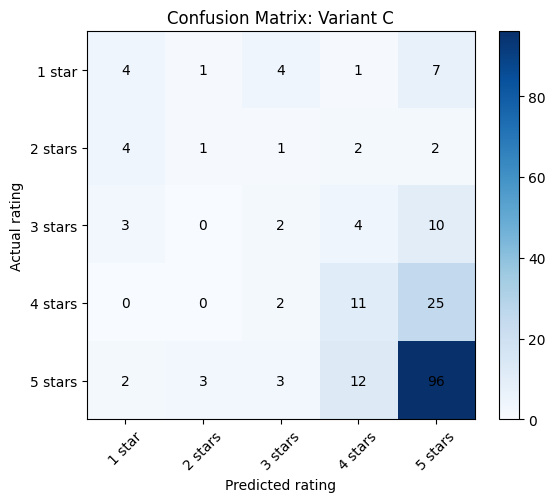

In [35]:
# Step 15: Detailed evaluation of Variant C

class_names = ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
print(classification_report(y_test_encoded, pred_c, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test_encoded, pred_c)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks(range(5), class_names, rotation=45)
plt.yticks(range(5), class_names)
for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.xlabel('Predicted rating')
plt.ylabel('Actual rating')
plt.title('Confusion Matrix: Variant C')
plt.tight_layout()
plt.show()

In [36]:
# Step 16: Collapse ratings into negative / neutral / positive

def to_sentiment(y):
    return np.where(y <= 1, 0, np.where(y == 2, 1, 2))   # 1-2 stars, 3 stars, 4-5 stars

y_train_3 = to_sentiment(y_train_encoded)
y_test_3 = to_sentiment(y_test_encoded)
y_train_3_oh = keras.utils.to_categorical(y_train_3, 3)

cw3 = dict(enumerate(compute_class_weight('balanced', classes=np.unique(y_train_3), y=y_train_3)))

tf.keras.utils.set_random_seed(42)
m3 = keras.Sequential([
    layers.Input(shape=(X_train_arr.shape[1],)),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dropout(0.5),
    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dense(3, activation='softmax')
])
m3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
m3.fit(X_train_arr, y_train_3_oh, epochs=50, batch_size=32, validation_split=0.2,
       class_weight=cw3, verbose=0,
       callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                                restore_best_weights=True)])

pred3 = np.argmax(m3.predict(X_test_arr, verbose=0), axis=1)
print("Majority-class baseline (always 'positive'):", round((y_test_3 == 2).mean(), 3))
print(classification_report(y_test_3, pred3,
      target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)'], zero_division=0))

Majority-class baseline (always 'positive'): 0.77
                precision    recall  f1-score   support

Negative (1-2)       0.62      0.37      0.47        27
   Neutral (3)       0.12      0.11      0.11        19
Positive (4-5)       0.83      0.90      0.87       154

      accuracy                           0.76       200
     macro avg       0.52      0.46      0.48       200
  weighted avg       0.74      0.76      0.74       200



### Part 3 Reflection: Neural Network Rating Classification

**Design choices:** TF-IDF features (3,000 unigrams and bigrams, fit on the training reviews only to avoid leakage) feed a multilayer perceptron with two ReLU hidden layers (64 and 32 units), dropout, and a softmax output with one unit per rating class. ReLU avoids vanishing gradients on sparse input, softmax produces probabilities for five mutually exclusive ratings, and categorical cross-entropy matches that output. A small network with dropout was chosen because there are only 797 training reviews.

**Baselines:** The test set is 58% five-star reviews, so always predicting "5 stars" scores 58.0% accuracy but only 0.147 macro F1. My original network scored 54.5% accuracy (macro F1 0.229), so it did not beat the majority baseline on accuracy. Plain logistic regression also scored 58.0% (macro F1 0.149) because it effectively predicts the majority class. Accuracy alone is therefore a misleading metric for this dataset, and I compare models by macro F1 and per-class recall.

**Experiments:** Class weights shifted predictions toward minority ratings and raised macro F1 from 0.254 to 0.273. Adding L2 regularization (1e-3), higher dropout (0.5) and early stopping produced the best network (test accuracy 0.570, macro F1 0.321), but it still overfit: 95.0% training accuracy against 56.2% validation accuracy. SGD with a high learning rate (0.1) diverged (test accuracy 0.185, worse than guessing the majority class). With a lower learning rate (0.01) it underfit within 15 epochs (train 0.432, validation 0.325, test 0.400), so Adam was the better optimizer for this sparse input. Balanced logistic regression reached a similar macro F1 (0.315), so the neural network adds little over a simple model at this dataset size. With 200 test reviews, accuracy has roughly ±3.5 points of sampling error, so differences of 1 to 2 points between variants are not meaningful.

**Performance by class:** For the best network, recall was 0.83 for 5-star reviews (F1 0.75) but only 0.24 for 1 star, 0.10 for 2 stars, 0.11 for 3 stars, and 0.29 for 4 stars. These classes are rare in the training data and use language close to their neighboring ratings, so the model often confuses them with five-star reviews. Collapsing ratings into negative, neutral, and positive gave 76% accuracy against a 77% majority baseline, but a macro F1 of 0.48 (versus about 0.29 for always predicting positive). Negative reviews were identified with precision 0.62 and recall 0.37, while neutral reviews were essentially unpredictable (F1 0.11).

**Improvements:** More labeled examples for the 1 to 3 star classes, pretrained text embeddings, and training for more epochs with a tuned learning rate would likely help most. For routing or monitoring in a business setting, predicting negative versus positive sentiment is more reliable than predicting exact star ratings, and the model's negative-review precision (0.62) makes it a reasonable first filter for flagging complaints.